# What Drives U.S. Gasoline Prices?

**Author:** Jobayer Ibne Saidur · Business Analytics, University of the Cumberlands

**Business question:** When crude oil moves, what happens to the price at the pump, how quickly, and does anything else matter?

This matters to anyone who buys or sells fuel: fleet and logistics managers budgeting fuel, airlines and retailers setting hedges, and households planning budgets.

**Data:** 7 public series from FRED and the U.S. Energy Information Administration (EIA), monthly, January 2005 to July 2026.

### Summary of findings
1. Crude oil alone explains **77%** of the gasoline price. Adding inventories, production, drilling and the economy raises that to 92%, but those extras do not help on new data.
2. **Every $1 per barrel on crude adds about 2.6¢ per gallon** at the pump.
3. **73%** of a crude move reaches the pump in the same month; essentially all of it by the next month.
4. Pump prices did **not** rise measurably faster than they fell ("rockets and feathers") at monthly frequency.
5. The gap between pump and crude prices widened by about **50¢ after 2021**, so older models under-predict today's prices.
6. Gasoline runs about **30¢ higher in May than in January**, regardless of crude.

## 1. Setup

The analysis uses `pandas` for data, `numpy` for the statistics, and `matplotlib` for charts. Regressions are written out in NumPy so every step is visible.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.float_format", "{:,.3f}".format)

RAW = Path("../data/raw")       # raw downloads from FRED and EIA
GAL_PER_BBL = 42                 # gallons in one barrel of crude oil

# chart style: consistent colors and clean axes
BLUE, ORANGE = "#2a78d6", "#eb6834"
INK2, GRID = "#52514e", "#e6e5e1"
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "axes.axisbelow": True,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.edgecolor": GRID, "xtick.color": INK2, "ytick.color": INK2, "axes.labelcolor": INK2,
    "lines.linewidth": 2, "figure.dpi": 110,
})

## 2. Load and clean the data

| Series | Source | ID |
|---|---|---|
| Regular gasoline retail price ($/gal) | FRED | GASREGW (weekly) |
| WTI crude oil price ($/bbl) | FRED | MCOILWTICO |
| Broad U.S. dollar index | FRED | DTWEXBGS (daily) |
| Industrial production index (demand) | FRED | INDPRO |
| U.S. crude oil inventories (thousand bbl) | EIA | MCRSTUS1 |
| U.S. crude oil production (thousand bbl/day) | EIA | MCRFPUS2 |
| U.S. crude oil drilling rigs | EIA | E_ERTRRO_XR0_NUS_C |

Weekly and daily series are averaged to months so everything lines up. The EIA files came as old-format `.xls`; they were converted to `.xlsx` with LibreOffice and both versions are in `data/raw/`.

In [2]:
def read_fred(name):
    df = pd.read_csv(RAW / f"{name}.csv", parse_dates=["observation_date"])
    s = pd.to_numeric(df[name], errors="coerce")
    s.index = df["observation_date"]
    return s.dropna().resample("MS").mean()          # monthly average

def read_eia(name):
    df = pd.read_excel(RAW / f"{name}.xlsx", sheet_name="Data 1", skiprows=3, header=None)
    s = pd.to_numeric(df[1], errors="coerce")
    s.index = pd.to_datetime(df[0]).dt.to_period("M").dt.to_timestamp()   # EIA dates are mid-month
    return s.dropna()

all_m = pd.concat({
    "gasoline_usd_gal":      read_fred("GASREGW"),
    "wti_usd_bbl":           read_fred("MCOILWTICO"),
    "dollar_index":          read_fred("DTWEXBGS"),
    "industrial_production": read_fred("INDPRO"),
    "crude_stocks_kbbl":     read_eia("MCRSTUS1m"),
    "crude_production_kbd":  read_eia("MCRFPUS2m"),
    "oil_rigs":              read_eia("E_ERTRRO_XR0_NUS_Cm"),
}, axis=1, sort=True).loc["1986":]
all_m.index.name = "month"

# modeling table: months where every driver is available
# (the dollar index only starts in late 2021, so it is analyzed separately)
d = all_m.dropna(subset=["gasoline_usd_gal", "wti_usd_bbl", "crude_stocks_kbbl",
                         "crude_production_kbd", "oil_rigs", "industrial_production"]).copy()
print(f"Modeling window: {d.index.min():%b %Y} to {d.index.max():%b %Y} ({len(d)} months)")
d.tail()

Modeling window: Jan 2005 to Jul 2026 (259 months)


,gasoline_usd_gal,wti_usd_bbl,dollar_index,industrial_production,crude_stocks_kbbl,crude_production_kbd,oil_rigs
month,,,,,,,
2026-03-01,3.638,91.380,119.920,101.734,"868,249.000","13,726.000",412.000
2026-04-01,4.103,100.320,119.036,102.577,"844,697.000","13,981.000",410.000
2026-05-01,4.479,102.130,118.779,102.723,"780,584.000","13,811.000",417.000
2026-06-01,4.050,84.810,120.083,102.961,"726,307.000","13,844.000",434.000
2026-07-01,3.932,80.460,120.597,103.201,"713,343.000","13,948.000",449.000


In [3]:
# put crude in the same unit as gasoline, and rescale drivers so coefficients are readable
d["crude_usd_gal"]  = d.wti_usd_bbl / GAL_PER_BBL      # $ per gallon
d["stocks_bn_bbl"]  = d.crude_stocks_kbbl / 1e6        # billion barrels
d["production_mbd"] = d.crude_production_kbd / 1e3     # million barrels per day
d["rigs_100"]       = d.oil_rigs / 100                 # hundreds of rigs
d["indpro"]         = d.industrial_production / 10     # per 10 index points
d[["gasoline_usd_gal", "wti_usd_bbl", "crude_stocks_kbbl", "crude_production_kbd",
   "oil_rigs", "industrial_production"]].describe().T

,count,mean,std,min,25%,50%,75%,max
gasoline_usd_gal,259.000,2.944,0.614,1.687,2.453,2.894,3.424,4.929
wti_usd_bbl,259.000,71.839,20.886,16.550,56.995,70.750,86.430,133.880
crude_stocks_kbbl,259.000,"1,017,016.517","114,685.388","713,343.000","987,121.000","1,041,243.000","1,084,757.000","1,230,105.000"
crude_production_kbd,259.000,"8,952.915","3,153.325","3,974.000","5,519.500","9,116.000","11,917.500","13,995.000"
oil_rigs,259.000,636.537,382.353,146.000,355.500,508.000,796.000,"1,593.000"
industrial_production,259.000,98.714,4.116,84.562,97.444,100.034,101.334,104.100


## 3. First look: gasoline vs. crude

Crude is converted to dollars per gallon (1 barrel = 42 gallons) so both lines share one axis. The shaded gap is everything between the oil well and the pump: refining, distribution, taxes and the retailer's margin.

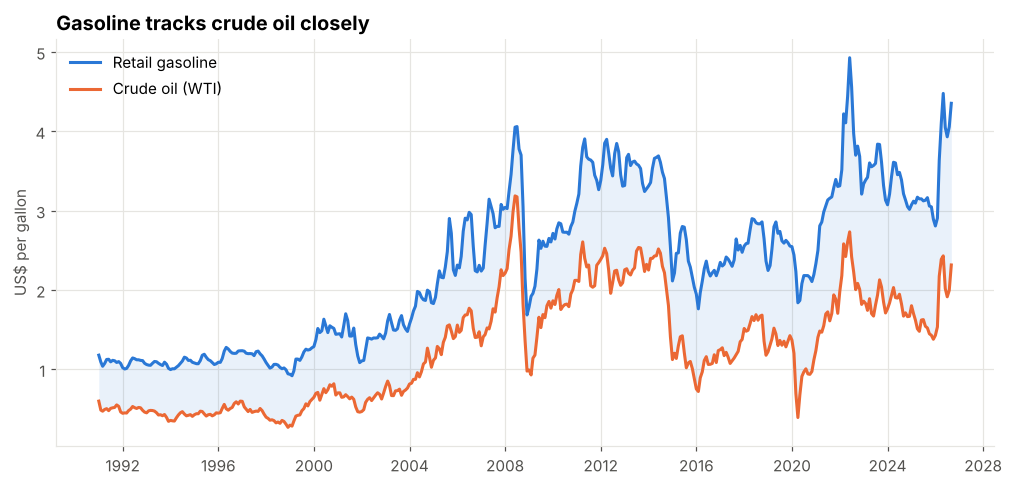

In [4]:
m = all_m[["gasoline_usd_gal", "wti_usd_bbl"]].dropna().loc["1991":]
crude_gal = m.wti_usd_bbl / GAL_PER_BBL

fig, ax = plt.subplots(figsize=(11, 4.8))
ax.fill_between(m.index, crude_gal, m.gasoline_usd_gal, color=BLUE, alpha=0.10, linewidth=0)
ax.plot(m.index, m.gasoline_usd_gal, color=BLUE, label="Retail gasoline")
ax.plot(m.index, crude_gal, color=ORANGE, label="Crude oil (WTI)")
ax.set_ylabel("US$ per gallon")
ax.legend(frameon=False, loc="upper left")
ax.set_title("Gasoline tracks crude oil closely")
plt.show()

In [5]:
corr = d[["gasoline_usd_gal", "wti_usd_bbl", "crude_stocks_kbbl", "crude_production_kbd",
          "oil_rigs", "industrial_production"]].corr()
corr["gasoline_usd_gal"].drop("gasoline_usd_gal").sort_values(ascending=False).to_frame("correlation with gasoline")

,correlation with gasoline
wti_usd_bbl,0.877
oil_rigs,0.409
industrial_production,0.285
crude_production_kbd,0.187
crude_stocks_kbbl,-0.543


Crude oil has by far the strongest relationship with gasoline (0.88). Inventories move the other way (more crude in storage, cheaper gas). Correlations can be misleading with trending data, though, so the next sections use regression.

## 4. Helper: regression with robust standard errors

Monthly prices are *autocorrelated* (this month looks like last month), which makes ordinary standard errors too optimistic. Newey-West (HAC) standard errors correct for that. This small function does ordinary least squares and returns coefficients, robust standard errors and R².

In [6]:
def ols(y, X, hac_lags=0):
    names = X.columns
    y, X = np.asarray(y, float), np.asarray(X, float)
    n, k = X.shape
    XtX_inv = np.linalg.inv(X.T @ X)
    b = XtX_inv @ X.T @ y
    e = y - X @ b
    if hac_lags:                                   # Newey-West covariance
        S = (X * e[:, None]).T @ (X * e[:, None])
        for L in range(1, hac_lags + 1):
            w = 1 - L / (hac_lags + 1)
            G = (X[L:] * e[L:, None]).T @ (X[:-L] * e[:-L, None])
            S += w * (G + G.T)
        V = XtX_inv @ S @ XtX_inv * n / (n - k)
    else:
        V = XtX_inv * (e @ e) / (n - k)
    se = np.sqrt(np.diag(V))
    r2 = 1 - (e @ e) / ((y - y.mean()) @ (y - y.mean()))
    return dict(b=pd.Series(b, names), se=pd.Series(se, names), V=pd.DataFrame(V, names, names),
                r2=r2, n=n, resid=pd.Series(e))

def add_const(df):
    return pd.concat([pd.Series(1.0, df.index, name="const"), df], axis=1)

def month_dummies(index):
    md_ = pd.get_dummies(index.month, prefix="m", drop_first=True).astype(float)
    md_.index = index
    return md_

def summary(res, rows):
    t = res["b"] / res["se"]
    return pd.DataFrame({"coef": res["b"], "robust_se": res["se"], "t_stat": t}).loc[rows]

## 5. Q1: How much does each driver explain?

**Model:** gasoline price = crude price + inventories + production + rig count + industrial production + month of year.

To rank the drivers, each one is dropped in turn and the loss in R² (explanatory power) is measured. A big loss means the driver carries information the others don't.

In [7]:
drivers = {"Crude oil price": "crude_usd_gal", "Crude inventories": "stocks_bn_bbl",
           "Crude production": "production_mbd", "Oil rig count": "rigs_100",
           "Industrial production (demand)": "indpro"}
cols = list(drivers.values())
months = month_dummies(d.index)

X_full = add_const(pd.concat([d[cols], months], axis=1))
full = ols(d.gasoline_usd_gal, X_full, hac_lags=12)
crude_only = ols(d.gasoline_usd_gal, add_const(d[["crude_usd_gal"]]), hac_lags=12)

print(f"R² crude only: {crude_only['r2']:.3f}")
print(f"R² full model: {full['r2']:.3f}")
summary(full, cols).rename(index={v: k for k, v in drivers.items()})

R² crude only: 0.769
R² full model: 0.922


,coef,robust_se,t_stat
Crude oil price,0.999,0.093,10.789
Crude inventories,-0.768,0.282,-2.719
Crude production,0.054,0.011,4.957
Oil rig count,0.013,0.011,1.171
Industrial production (demand),-0.006,0.065,-0.089


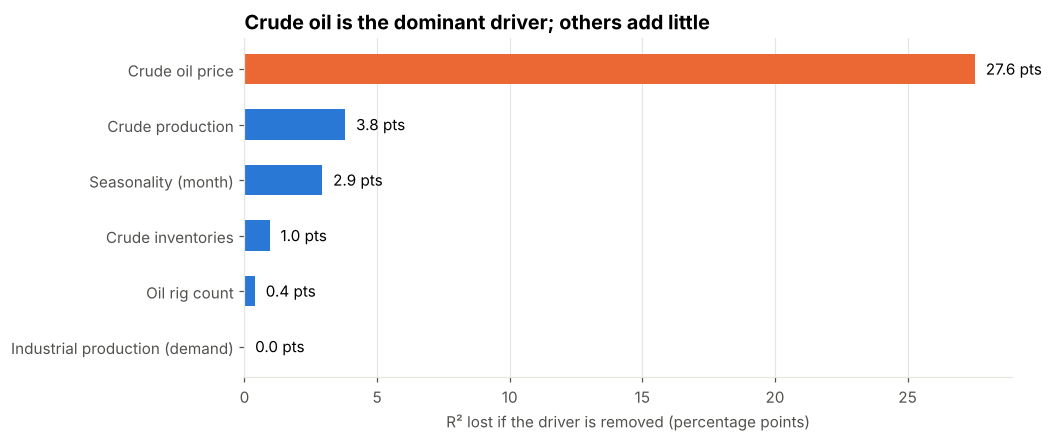

In [8]:
importance = {}
for label, col in drivers.items():
    importance[label] = full["r2"] - ols(d.gasoline_usd_gal, X_full.drop(columns=col))["r2"]
importance["Seasonality (month)"] = full["r2"] - ols(d.gasoline_usd_gal, X_full.drop(columns=months.columns))["r2"]
imp = pd.Series(importance).sort_values()

fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(imp.index, imp * 100, color=[ORANGE if k == "Crude oil price" else BLUE for k in imp.index], height=0.55)
for i, v in enumerate(imp):
    ax.text(v * 100 + 0.4, i, f"{v*100:.1f} pts", va="center")
ax.set_xlabel("R² lost if the driver is removed (percentage points)")
ax.grid(axis="y", visible=False)
ax.set_title("Crude oil is the dominant driver; others add little")
plt.show()

**Takeaway:** Removing crude costs 27.6 points of R²; nothing else costs more than 4. Inventories have the expected negative sign and are significant, but small. Industrial production adds nothing once crude is known. Crude production's positive coefficient most likely reflects its long upward trend rather than a real effect (it fails the out-of-sample test in section 9).

## 6. Q2: How much and how fast does a crude move reach the pump?

Here the model uses **monthly changes** instead of levels. Working in changes avoids spurious links between series that both trend over time. Gasoline's change this month is regressed on crude's change this month and in each of the previous 3 months (a *distributed-lag* model). Adding the lag effects up gives the cumulative pass-through.

In [9]:
LAGS = 3
chg = d.diff()
dl = pd.DataFrame({"d_gas": chg.gasoline_usd_gal})
for L in range(LAGS + 1):
    dl[f"d_crude_L{L}"] = chg.crude_usd_gal.shift(L)
dl["d_stocks"], dl["d_prod"] = chg.stocks_bn_bbl, chg.production_mbd
dl["d_rigs"], dl["d_indpro"] = chg.rigs_100, chg.indpro
dl = dl.dropna()

X_dl = add_const(pd.concat([dl.drop(columns="d_gas"), month_dummies(dl.index)], axis=1))
pt = ols(dl.d_gas, X_dl, hac_lags=3)

lag_names = [f"d_crude_L{L}" for L in range(LAGS + 1)]
cum = pt["b"][lag_names].cumsum()
c = np.ones(len(lag_names))
long_run = cum.iloc[-1]
long_run_se = np.sqrt(c @ pt["V"].loc[lag_names, lag_names].values @ c)

print(f"Months used: {pt['n']},  R² = {pt['r2']:.3f}")
print(f"Long-run pass-through: {long_run:.3f} (robust SE {long_run_se:.3f})")
print(f"Rule of thumb: +$1/bbl crude -> +{100 * long_run / GAL_PER_BBL:.1f} cents/gal gasoline")
pd.DataFrame({"effect this lag": pt["b"][lag_names].values, "cumulative": cum.values},
             index=["Same month", "+1 month", "+2 months", "+3 months"])

Months used: 255,  R² = 0.727
Long-run pass-through: 1.076 (robust SE 0.095)
Rule of thumb: +$1/bbl crude -> +2.6 cents/gal gasoline


,effect this lag,cumulative
Same month,0.726,0.726
+1 month,0.387,1.113
+2 months,-0.014,1.099
+3 months,-0.023,1.076


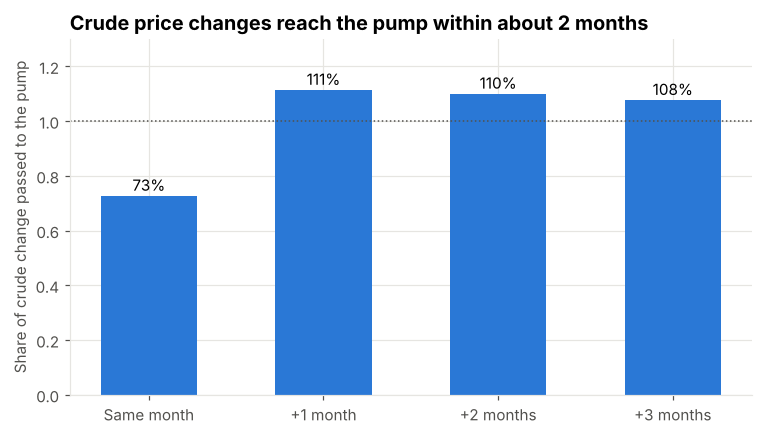

In [10]:
fig, ax = plt.subplots(figsize=(8, 4.2))
labels = ["Same month", "+1 month", "+2 months", "+3 months"]
bars = ax.bar(labels, cum.values, color=BLUE, width=0.55)
for bar, v in zip(bars, cum.values):
    ax.text(bar.get_x() + bar.get_width() / 2, v + 0.02, f"{v:.0%}", ha="center")
ax.axhline(1, color=INK2, linewidth=1, linestyle=":")
ax.set_ylim(0, 1.3)
ax.set_ylabel("Share of crude change passed to the pump")
ax.set_title("Crude price changes reach the pump within about 2 months")
plt.show()

**Takeaway:** About 73% of a crude price change shows up at the pump in the same month and the rest arrives the next month. In total, slightly more than 100% passes through, so **$1 per barrel on crude ≈ 2.6¢ per gallon** at the pump.

## 7. Q3: Do pump prices rise like rockets and fall like feathers?

A common complaint is that gas prices jump quickly when crude rises but drift down slowly when crude falls. To test it, crude changes are split into increases and decreases, each with its own lag pattern. The test asks whether the two total effects differ.

In [11]:
up, down = chg.crude_usd_gal.clip(lower=0), chg.crude_usd_gal.clip(upper=0)
af = pd.DataFrame({"d_gas": chg.gasoline_usd_gal})
for L in range(LAGS + 1):
    af[f"up_L{L}"], af[f"dn_L{L}"] = up.shift(L), down.shift(L)
af = af.dropna()
asy = ols(af.d_gas, add_const(pd.concat([af.drop(columns="d_gas"), month_dummies(af.index)], axis=1)), hac_lags=3)

def compare(res, a, b):
    idx = res["b"].index
    w = np.array([(i in a) - (i in b) for i in idx], float)
    diff = w @ res["b"].values
    return diff, diff / np.sqrt(w @ res["V"].values @ w)

up_n, dn_n = [f"up_L{L}" for L in range(LAGS + 1)], [f"dn_L{L}" for L in range(LAGS + 1)]
same, t_same = compare(asy, ["up_L0"], ["dn_L0"])
total, t_total = compare(asy, up_n, dn_n)
print(f"Same-month difference (rises minus falls): {same:+.3f}, t = {t_same:.2f}")
print(f"Total difference over 4 months:            {total:+.3f}, t = {t_total:.2f}")
pd.DataFrame({"crude rises": asy["b"][up_n].cumsum().values,
              "crude falls": asy["b"][dn_n].cumsum().values},
             index=["Same month", "+1 month", "+2 months", "+3 months"])

Same-month difference (rises minus falls): -0.164, t = -1.04
Total difference over 4 months:            +0.178, t = 0.95


,crude rises,crude falls
Same month,0.637,0.801
+1 month,1.009,1.196
+2 months,1.129,1.094
+3 months,1.218,1.040


**Takeaway:** Neither difference is statistically significant (|t| ≈ 1, well below 2). At monthly frequency the data do not support "rockets and feathers," so the scenario model uses the same path for increases and decreases. Weekly data might reveal shorter-lived asymmetry.

## 8. Q4: Seasonality and the retail spread

**Seasonality:** take what's left of the gasoline price after removing the crude effect, and average it by calendar month.

**Spread:** gasoline minus crude ($/gal). This covers refining, distribution, taxes and retail margin.

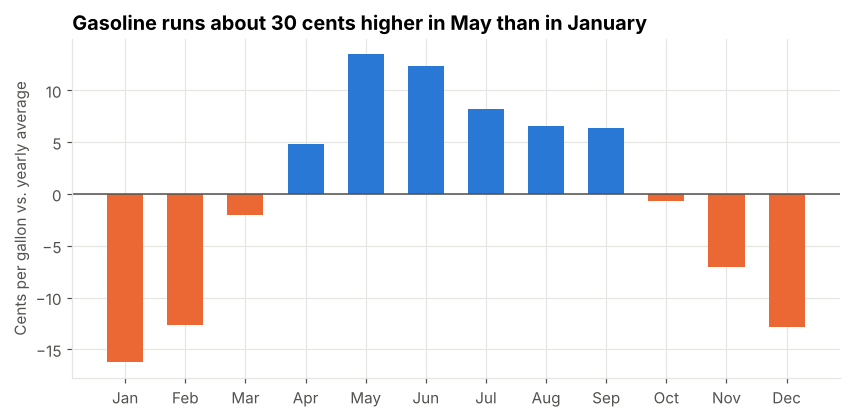

In [12]:
resid = pd.Series(crude_only["resid"].values, d.index)
seas = resid.groupby(d.index.month).mean()
seas = (seas - seas.mean()) * 100   # cents vs. yearly average
seas.index = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(seas.index, seas, color=[BLUE if v >= 0 else ORANGE for v in seas], width=0.6)
ax.axhline(0, color=INK2, linewidth=1)
ax.set_ylabel("Cents per gallon vs. yearly average")
ax.set_title("Gasoline runs about 30 cents higher in May than in January")
plt.show()

Average spread 2005-2019: $1.11/gal   2022 onward: $1.61/gal   (+51 cents)


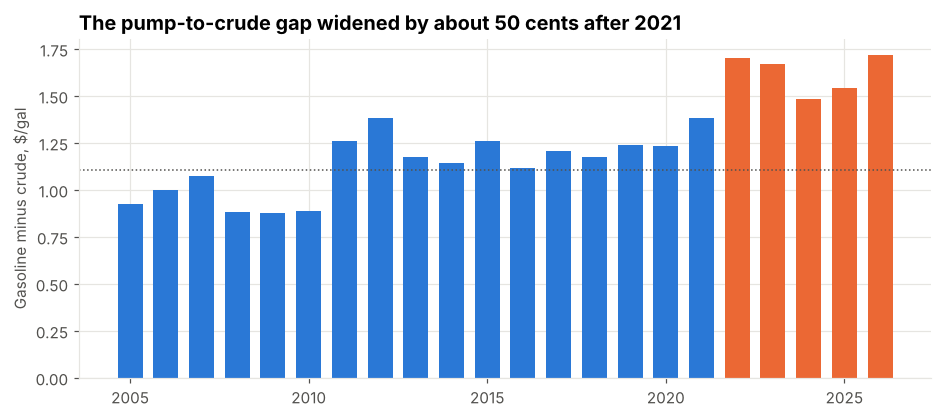

In [13]:
d["spread_usd_gal"] = d.gasoline_usd_gal - d.crude_usd_gal
by_year = d.spread_usd_gal.groupby(d.index.year).mean()
before, after = d.spread_usd_gal[:"2019"].mean(), d.spread_usd_gal["2022":].mean()
print(f"Average spread 2005-2019: ${before:.2f}/gal   2022 onward: ${after:.2f}/gal   (+{100*(after-before):.0f} cents)")

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(by_year.index, by_year, color=[ORANGE if y >= 2022 else BLUE for y in by_year.index], width=0.7)
ax.axhline(before, color=INK2, linewidth=1, linestyle=":")
ax.set_ylabel("Gasoline minus crude, $/gal")
ax.set_title("The pump-to-crude gap widened by about 50 cents after 2021")
plt.show()

**Takeaway:** Spring and summer driving season (plus the switch to summer-blend fuel) adds about 30¢ versus mid-winter. Separately, the spread jumped from about $1.11 to $1.61 per gallon after 2021, consistent with tighter U.S. refining capacity. That shift matters for the next test.

## 9. Q5: Does the model hold up on data it has never seen?

Both models are trained only on 2005 to 2019, then asked to predict 2020 to 2026. A naive benchmark ("same price as last month") is included for honesty.

In [14]:
train = d.index < "2020-01-01"
test_y = d.gasoline_usd_gal[~train]

bt_full = ols(d.gasoline_usd_gal[train], X_full[train])
pred_full = X_full[~train].values @ bt_full["b"].values

X_c = add_const(d[["crude_usd_gal"]])
bt_c = ols(d.gasoline_usd_gal[train], X_c[train])
pred_c = X_c[~train].values @ bt_c["b"].values
naive = d.gasoline_usd_gal.shift(1)[~train]

pd.DataFrame({
    "avg error ($/gal)": [np.mean(np.abs(test_y - pred_full)), np.mean(np.abs(test_y - pred_c)), np.mean(np.abs(test_y - naive))],
    "avg bias ($/gal)":  [np.mean(test_y - pred_full), np.mean(test_y - pred_c), np.mean(test_y - naive)],
}, index=["Full model (all drivers)", "Crude only", "Naive: last month's price"])

,avg error ($/gal),avg bias ($/gal)
Full model (all drivers),0.618,0.618
Crude only,0.415,0.413
Naive: last month's price,0.150,0.017


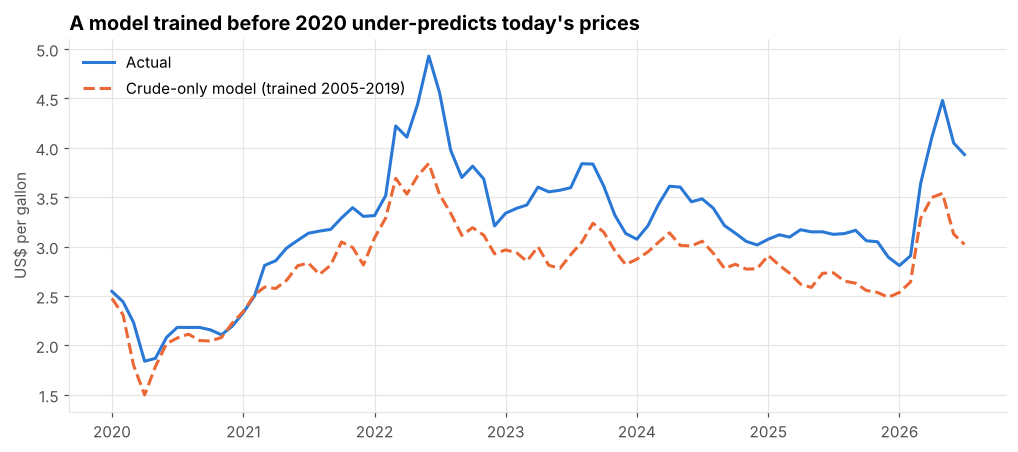

In [15]:
fig, ax = plt.subplots(figsize=(11, 4.4))
ax.plot(test_y.index, test_y, color=BLUE, label="Actual")
ax.plot(test_y.index, pred_c, color=ORANGE, linestyle="--", label="Crude-only model (trained 2005-2019)")
ax.set_ylabel("US$ per gallon")
ax.legend(frameon=False, loc="upper left")
ax.set_title("A model trained before 2020 under-predicts today's prices")
plt.show()

**Takeaway:** The crude-only model tracks the *shape* of prices well but sits about 41¢ too low, which is almost exactly the post-2021 spread increase. Adding the other drivers makes it worse, confirming they were overfitting the past. Last month's price is the best one-month-ahead forecast, so this model is best used for explanation and scenarios, not short-term forecasting.

## 10. Q6: Scenario: what if crude jumps 20%?

The pass-through path from section 6 is applied to a crude price shock, starting from the latest month with both prices (September 2026). The range is a 95% interval on the long-run pass-through.

In [16]:
latest = all_m[["wti_usd_bbl", "gasoline_usd_gal"]].dropna()
base_month, base = latest.index[-1], latest.iloc[-1]
print(f"Starting point ({base_month:%b %Y}): WTI ${base.wti_usd_bbl:.2f}/bbl, gasoline ${base.gasoline_usd_gal:.3f}/gal")

def scenario(pct, wti=base.wti_usd_bbl, gas=base.gasoline_usd_gal):
    """Gasoline price path after crude changes by `pct` percent."""
    d_crude_gal = wti * pct / 100 / GAL_PER_BBL
    path = cum.values * d_crude_gal
    lo = gas + d_crude_gal * (long_run - 1.96 * long_run_se)
    hi = gas + d_crude_gal * (long_run + 1.96 * long_run_se)
    return {"crude change": f"{pct:+d}%", "new WTI": round(float(wti) * (1 + pct / 100), 2),
            "gas change, same month": round(float(path[0]), 2), "gas change, month +1": round(float(path[1]), 2),
            "settled gas price": round(float(gas + path[-1]), 2),
            "95% range": f"${min(lo, hi):.2f} to ${max(lo, hi):.2f}"}

pd.DataFrame([scenario(p) for p in [-30, -20, -10, 10, 20, 30]]).set_index("crude change")

Starting point (Sep 2026): WTI $97.31/bbl, gasoline $4.355/gal


,new WTI,"gas change, same month","gas change, month +1",settled gas price,95% range
crude change,,,,,
-30%,68.120,-0.500,-0.770,3.610,$3.48 to $3.74
-20%,77.850,-0.340,-0.520,3.860,$3.77 to $3.94
-10%,87.580,-0.170,-0.260,4.110,$4.06 to $4.15
+10%,107.040,0.170,0.260,4.600,$4.56 to $4.65
+20%,116.770,0.340,0.520,4.850,$4.77 to $4.94
+30%,126.500,0.500,0.770,5.100,$4.97 to $5.23


Try your own: change the number below and re-run the cell.

In [17]:
scenario(20)

{'crude change': '+20%', 'new WTI': 116.77, 'gas change, same month': 0.34, 'gas change, month +1': 0.52, 'settled gas price': 4.85, '95% range': '$4.77 to $4.94'}

## 11. The dollar (short window)

The broad dollar index file covers only October 2021 onward, so it is checked separately rather than in the main model.

In [18]:
dw = all_m[["wti_usd_bbl", "dollar_index", "gasoline_usd_gal"]].dropna()
r = np.log(dw).diff().dropna()
print(f"{dw.index.min():%b %Y} to {dw.index.max():%b %Y}, {len(dw)} months")
print(f"Correlation of monthly % changes, dollar vs WTI:      {r.dollar_index.corr(r.wti_usd_bbl):.2f}")
print(f"Correlation of monthly % changes, dollar vs gasoline: {r.dollar_index.corr(r.gasoline_usd_gal):.2f}")

Oct 2021 to Sep 2026, 60 months
Correlation of monthly % changes, dollar vs WTI:      0.09
Correlation of monthly % changes, dollar vs gasoline: 0.14


Both correlations are weak over this period, so the dollar is not a meaningful short-run driver here. A longer history would be needed to say more.

## 12. Conclusions and recommendations

| Audience | Recommendation |
|---|---|
| Fleet, logistics, airlines | Convert crude futures into fuel budgets with **2.6¢/gal per $1/bbl**, and expect the impact within 1 to 2 months. |
| Risk / treasury | Crude hedges cover most gasoline cost risk because pass-through is near one-for-one. The leftover risk is the retail spread, which crude hedges do not cover. |
| Pricing & forecasting teams | Model the spread separately. Relationships estimated before 2020 are biased low by 40 to 50¢. |
| Planning | Budget about 30¢/gal more for late spring than mid-winter, independent of crude. |

### Limitations
- Monthly averages can hide week-to-week dynamics, including short-lived "rockets and feathers."
- Scenarios hold the retail spread fixed; refinery outages, hurricanes and tax changes are not modeled.
- The dollar index history in this dataset is short (60 months).
- This is an explanatory model. For next-month forecasts, last month's price is more accurate.